In [12]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from models.extramlem import extraCNN
from utils.image_ops import normalise, sum_normalise
from utils.mlem import mlem_reco
from skimage.transform import resize, radon, iradon

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


In [13]:
''' Fitting Gaussian to sinogram
from scipy.optimize import curve_fit
from utils.noise_fcn import gaussian

counts_bin = sino.ravel()
counts_bin = counts_bin[np.isfinite(counts_bin)]

# Exclude background/empty LORs; adjust threshold after inspecting the data
thresh = 0
vals = counts_bin[counts_bin > thresh]

n_bins = 50
bin_heights, bin_edges = np.histogram(vals, bins=n_bins)
bin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])

mask = bin_heights > 0
x = bin_centres[mask]
y = bin_heights[mask].astype(float)
sigma_w = np.sqrt(y)

# Data-driven initial guesses
mu0 = np.average(x, weights=y)
sigma0 = np.sqrt(np.average((x - mu0)**2, weights=y))
A0 = y.max()

# Optional: restrict the fit to the region around the peak
peak = x[np.argmax(y)]
win = (x > peak - 2.5 * sigma0) & (x < peak + 2.5 * sigma0)

popt, pcov = curve_fit(
    gaussian, x[win], y[win],
    p0=[mu0, A0, sigma0],   # (mean, amplitude, std), per your gaussian signature
    sigma=sigma_w[win],
    absolute_sigma=True,
    bounds=([x.min(), 0, 1e-9], [x.max(), np.inf, np.inf]),
    maxfev=20000,
)
mu_fit, A_fit, sigma_fit = popt
perr = np.sqrt(np.diag(pcov))
print(f"mu = {mu_fit:.2f} ± {perr[0]:.2f}, sigma = {sigma_fit:.2f} ± {perr[2]:.2f}")
print(f"Relative noise: {1 / np.sqrt(mu_fit):.2f}")

x_smooth = np.linspace(x.min(), x.max(), 500)
plt.hist(vals, bins=bin_edges, edgecolor="none")
plt.plot(x_smooth, gaussian(x_smooth, *popt), color="orange", lw=2, label="Gaussian fit")
plt.xlabel("Counts per bin")
plt.ylabel("Number of bins")
plt.legend()
plt.tight_layout()
plt.savefig("/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/Plots/fig_6_4_regenerated.png", dpi=200)
plt.show()'''

' Fitting Gaussian to sinogram\nfrom scipy.optimize import curve_fit\nfrom utils.noise_fcn import gaussian\n\ncounts_bin = sino.ravel()\ncounts_bin = counts_bin[np.isfinite(counts_bin)]\n\n# Exclude background/empty LORs; adjust threshold after inspecting the data\nthresh = 0\nvals = counts_bin[counts_bin > thresh]\n\nn_bins = 50\nbin_heights, bin_edges = np.histogram(vals, bins=n_bins)\nbin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])\n\nmask = bin_heights > 0\nx = bin_centres[mask]\ny = bin_heights[mask].astype(float)\nsigma_w = np.sqrt(y)\n\n# Data-driven initial guesses\nmu0 = np.average(x, weights=y)\nsigma0 = np.sqrt(np.average((x - mu0)**2, weights=y))\nA0 = y.max()\n\n# Optional: restrict the fit to the region around the peak\npeak = x[np.argmax(y)]\nwin = (x > peak - 2.5 * sigma0) & (x < peak + 2.5 * sigma0)\n\npopt, pcov = curve_fit(\n    gaussian, x[win], y[win],\n    p0=[mu0, A0, sigma0],   # (mean, amplitude, std), per your gaussian signature\n    sigma=sigma_w[win],\n

In [14]:
'''base = "/scratch/bggjem001/pet_datasets"

#Loading test images (min-max normalised for CNN input compatibility)
#test_ims_sn = np.load(f"{base}/datasets/images_test_sn.npy")
test_ims_sn = np.load(f"{base}/Ryan_Data/truth_blurred_4_182.npy")
test_ims_sn = test_ims_sn[None, ...]  
test_ims_sn = np.rot90(test_ims_sn, k=3, axes=(-2, -1)).copy()


mlem_test_raw = np.load(f"{base}/Ryan_Data/reco_4_182.npy")
mlem_test_raw = mlem_test_raw[None, ...] 
mlem_test_raw = np.rot90(mlem_test_raw, k=3, axes=(-2, -1)).copy()'''

'base = "/scratch/bggjem001/pet_datasets"\n\n#Loading test images (min-max normalised for CNN input compatibility)\n#test_ims_sn = np.load(f"{base}/datasets/images_test_sn.npy")\ntest_ims_sn = np.load(f"{base}/Ryan_Data/truth_blurred_4_182.npy")\ntest_ims_sn = test_ims_sn[None, ...]  \ntest_ims_sn = np.rot90(test_ims_sn, k=3, axes=(-2, -1)).copy()\n\n\nmlem_test_raw = np.load(f"{base}/Ryan_Data/reco_4_182.npy")\nmlem_test_raw = mlem_test_raw[None, ...] \nmlem_test_raw = np.rot90(mlem_test_raw, k=3, axes=(-2, -1)).copy()'

In [15]:


base = "/scratch/bggjem001/pet_datasets"

#Loading test images
test_ims_sn = np.load(f"{base}/Ryan_Data/reco_4_182.npy")
test_ims_sn = test_ims_sn[None, ...]  
test_ims_sn = np.rot90(test_ims_sn, k=3, axes=(-2, -1)).copy()

scale = 182*182

#Sum-normalised version of MLEM reconstructions for metric comparison
test_ims_sn = np.array([sum_normalise(im) for im in test_ims_sn])
test_ims_sn = test_ims_sn * scale

nxd = 182
theta = np.linspace(0., 180., max(nxd, 180), endpoint=False)

sino = radon(test_ims_sn[0], theta=theta, circle=True)

In [16]:
'''plt.imshow(test_ims_sn[0])
plt.axis("off")'''

'plt.imshow(test_ims_sn[0])\nplt.axis("off")'

In [17]:
#plt.imshow(sino)

(-0.5, 181.5, 181.5, -0.5)

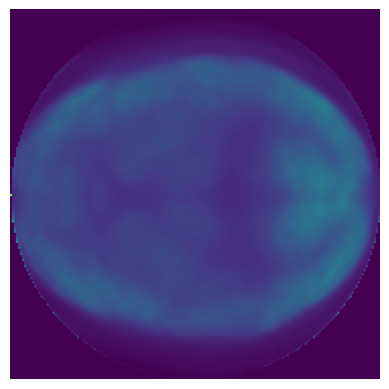

In [18]:
theta = np.linspace(0., 180., max(nxd, 180), endpoint=False)

mlem_test_raw = mlem_reco(sino, theta, 33)
#mlem_test_raw = np.load("/scratch/bggjem001/pet_datasets/Ryan_Data/reco_4_182.npy")
mlem_test_raw = mlem_test_raw[None, ...] 
#mlem_test_raw = np.rot90(mlem_test_raw, k=3, axes=(-2, -1)).copy()

plt.imshow(mlem_test_raw[0])
plt.axis("off")

In [ ]:


#Loading the trained extra-CNN model
model = extraCNN().to(device)
model.load_state_dict(torch.load(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/model_weights/noisy0.5_extra33_sn1.pth", map_location=device))
model.eval()

extraCNN(
  (CNN_denoise): Sequential(
    (0): Conv2d(1, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): PReLU(num_parameters=1)
    (2): Conv2d(3, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)

In [20]:
scale = 182*182

#Sum-normalised version of MLEM reconstructions for metric comparison
mlem_test_sn = np.array([sum_normalise(im) for im in mlem_test_raw])
mlem_test_scaled = mlem_test_sn * scale

In [21]:
with torch.no_grad():
    
    enhanced = []
    x = torch.from_numpy(mlem_test_scaled[0]).unsqueeze(0).unsqueeze(0).float().to(device)
    out = model(x)
    enhanced.append(out.squeeze().cpu().numpy())

enhanced = np.array(enhanced) / scale

In [22]:
#plt.imshow(enhanced[0])

In [23]:
scale = 182*182

#Sum-normalised version of MLEM reconstructions for metric comparison
en_sn = np.array([sum_normalise(im) for im in enhanced])
en_sn = en_sn * scale

mlem_n = mlem_test_scaled[0]
cnn_n  = en_sn[0] 
gt_n   = test_ims_sn[0]              # already [0,1]
# then metrics with data_range=1.0

global_dr = float(test_ims_sn.max() - test_ims_sn.min())

#NMSE
nmse_mlem = mean_squared_error(gt_n, mlem_n) / np.var(gt_n)

#Getting SSIM vals for normal MLEM
ssim_mlem = ssim(gt_n, mlem_n, data_range=global_dr)

#Getting PSNR vals for normal MLEM
psnr_mlem = psnr(gt_n, mlem_n, data_range=global_dr)

#NMSE
nmse_extra = mean_squared_error(gt_n, cnn_n) / np.var(gt_n)

#SSIM for extra-CNN
ssim_extra = ssim(gt_n, cnn_n, data_range=global_dr)

#PSNR for extra-CNN
psnr_extra = psnr(gt_n, cnn_n, data_range=global_dr)

print(psnr_extra, psnr_mlem)

29.82498143996263 29.406576641955727


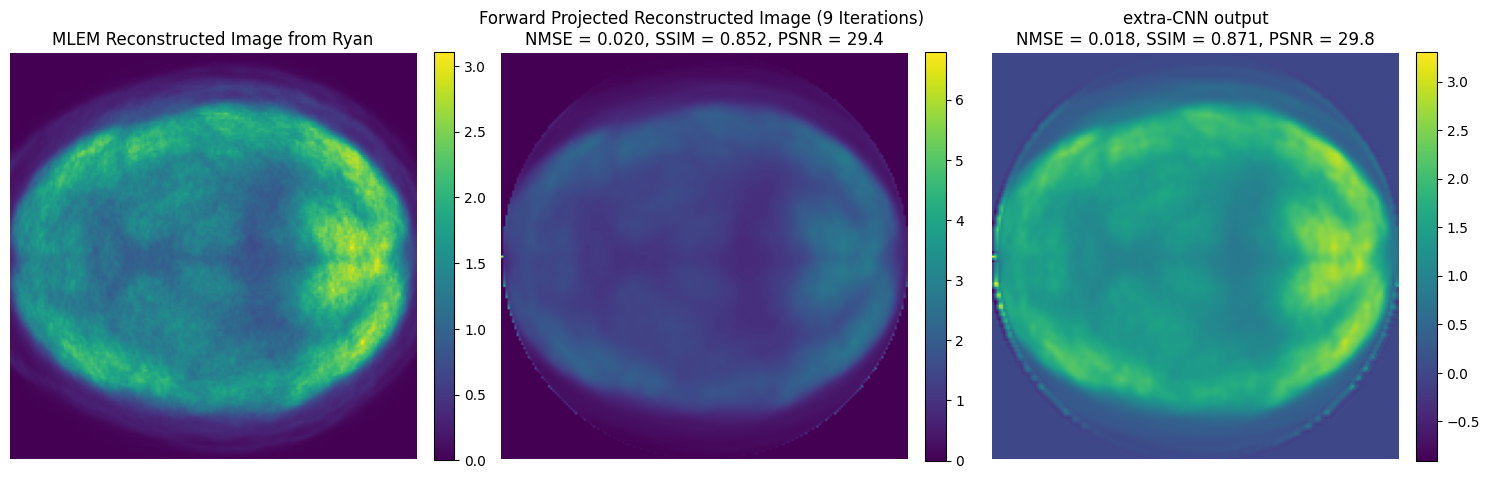

In [24]:
fig2, ax2 = plt.subplots(1, 3, figsize=(15, 5))
panels = [
    (gt_n,    "MLEM Reconstructed Image from Ryan"),
    (mlem_n, f"Forward Projected Reconstructed Image (9 Iterations) \nNMSE = {nmse_mlem:.3f}, SSIM = {ssim_mlem:.3f}, PSNR = {psnr_mlem:.1f}"),
    (cnn_n,   f"extra-CNN output\nNMSE = {nmse_extra:.3f}, SSIM = {ssim_extra:.3f}, PSNR = {psnr_extra:.1f}"),
]
for a, (img, title) in zip(ax2, panels):
    m = a.imshow(img)
    a.set_title(title)
    a.axis("off")
    fig2.colorbar(m, ax=a, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/Plots/ryan_slice_gt_input_output.png", dpi=300, bbox_inches="tight")
plt.show()

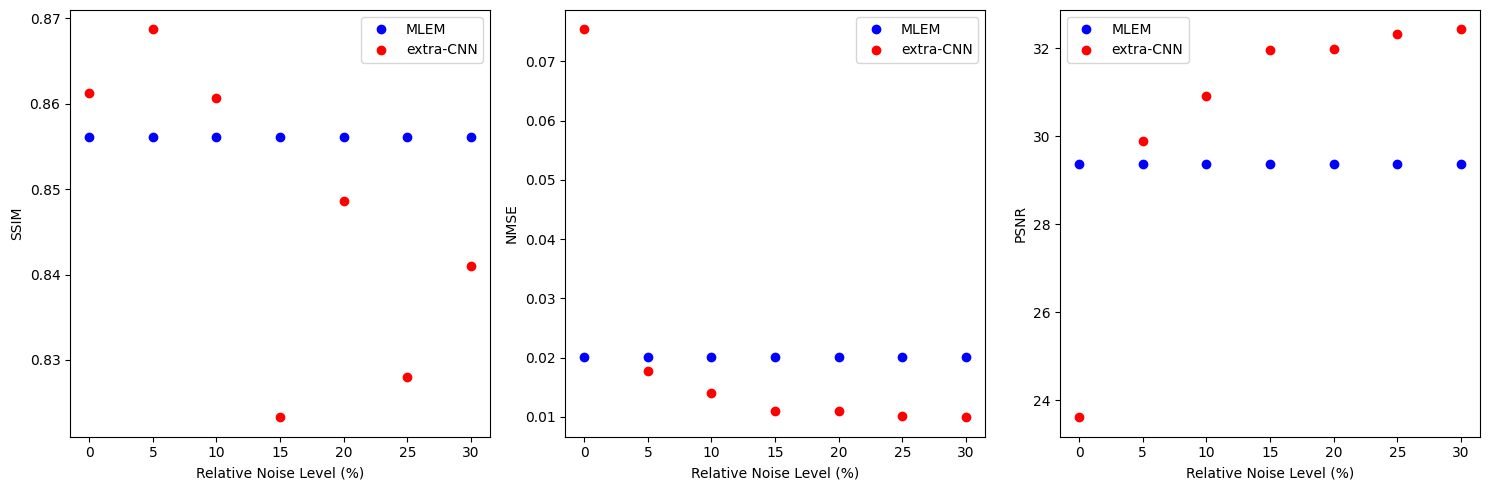

In [25]:


noise_levels = [0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]

idx = 0              # the single slice from Ryan
display_noise = 0    # which trained model's output to visualise (0 = clean)

ssim_mlem, ssim_extra = [], []
psnr_mlem, psnr_extra = [], []
nmse_mlem, nmse_extra = [], []

base = "/scratch/bggjem001/pet_datasets"

#Loading test images
test_ims_sn = np.load(f"{base}/Ryan_Data/reco_4_182.npy")
test_ims_sn = test_ims_sn[None, ...]  
test_ims_sn = np.rot90(test_ims_sn, k=3, axes=(-2, -1)).copy()

scale = 182*182

#Sum-normalised version of MLEM reconstructions for metric comparison
test_ims_sn = np.array([sum_normalise(im) for im in test_ims_sn])
test_ims_sn = test_ims_sn * scale

nxd = 182
theta = np.linspace(0., 180., max(nxd, 180), endpoint=False)

sino = radon(test_ims_sn[0], theta=theta, circle=True)

theta = np.linspace(0., 180., max(nxd, 180), endpoint=False)

mlem_test_raw = mlem_reco(sino, theta, 36)
#mlem_test_raw = np.load("/scratch/bggjem001/pet_datasets/Ryan_Data/reco_4_182.npy")
mlem_test_raw = mlem_test_raw[None, ...] 

#Sum-normalised version of MLEM reconstructions for metric comparison
mlem_test_sn = np.array([sum_normalise(im) for im in mlem_test_raw])
mlem_test_scaled = mlem_test_sn * scale

for noise in noise_levels:

    prefix = "clean" if noise == 0 else f"noisy{noise}"
    mlem_prefix = '' if noise == 0 else f"noisy{noise}_"

    #Loading the trained extra-CNN model
    model = extraCNN().to(device)
    model.load_state_dict(torch.load(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/model_weights/{prefix}_extra36_sn1.pth", map_location=device))
    model.eval()

    with torch.no_grad():
        enhanced = []
        x = torch.from_numpy(mlem_test_scaled[0]).unsqueeze(0).unsqueeze(0).float().to(device)
        out = model(x)
        enhanced.append(out.squeeze().cpu().numpy())

    enhanced = np.array(enhanced) / scale

    en_sn = np.array([sum_normalise(im) for im in enhanced])
    enhanced = en_sn * scale

    global_dr = float(test_ims_sn.max() - test_ims_sn.min())

    #NMSE
    nmse_vals =mean_squared_error(test_ims_sn[0], mlem_test_scaled[0]) / np.var(test_ims_sn[0])
    nmse_mlem.append(nmse_vals)

    #Getting SSIM vals for normal MLEM
    

    ssim_vals=ssim(test_ims_sn[0], mlem_test_scaled[0], data_range=global_dr)

    ssim_mlem.append(ssim_vals)

    #Getting PSNR vals for normal MLEM
    
    psnr_vals=psnr(test_ims_sn[0], mlem_test_scaled[0], data_range=global_dr)

    psnr_mlem.append(psnr_vals)

    #NMSE
    nmse_vals = mean_squared_error(test_ims_sn[0], enhanced[0]) / np.var(test_ims_sn[0])
    nmse_extra.append(nmse_vals)

    #SSIM for extra-CNN
   
    ssim_vals=ssim(test_ims_sn[0], enhanced[0], data_range=global_dr)

    ssim_extra.append(ssim_vals)

    #PSNR for extra-CNN
    psnr_vals = psnr(test_ims_sn[0], enhanced[0], data_range=global_dr)

    psnr_extra.append(psnr_vals)

    del enhanced, model
    torch.cuda.empty_cache()

noise_levels = np.array(noise_levels)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].plot(noise_levels*10, ssim_mlem, 'bo', label="MLEM")
axes[0].plot(noise_levels*10, ssim_extra, 'ro', label="extra-CNN")
axes[0].set_xlabel("Relative Noise Level (%)")
axes[0].set_ylabel("SSIM")
axes[0].legend()

axes[1].plot(noise_levels*10, nmse_mlem, 'bo', label="MLEM")
axes[1].plot(noise_levels*10, nmse_extra, 'ro', label="extra-CNN")
axes[1].set_xlabel("Relative Noise Level (%)")
axes[1].set_ylabel("NMSE")
axes[1].legend()

axes[2].plot(noise_levels*10, psnr_mlem, 'bo', label="MLEM")
axes[2].plot(noise_levels*10, psnr_extra, 'ro', label="extra-CNN")
axes[2].set_xlabel("Relative Noise Level (%)")
axes[2].set_ylabel("PSNR")
axes[2].legend()

plt.tight_layout()
plt.savefig(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/Plots/metrics_vs_noise_ryan.png", dpi=300, bbox_inches='tight')
plt.show()

Evaluating iteration 3
Evaluating iteration 6
Evaluating iteration 9
Evaluating iteration 12
Evaluating iteration 15
Evaluating iteration 18
Evaluating iteration 21
Evaluating iteration 24
Evaluating iteration 27
Evaluating iteration 30
Evaluating iteration 33
Evaluating iteration 36


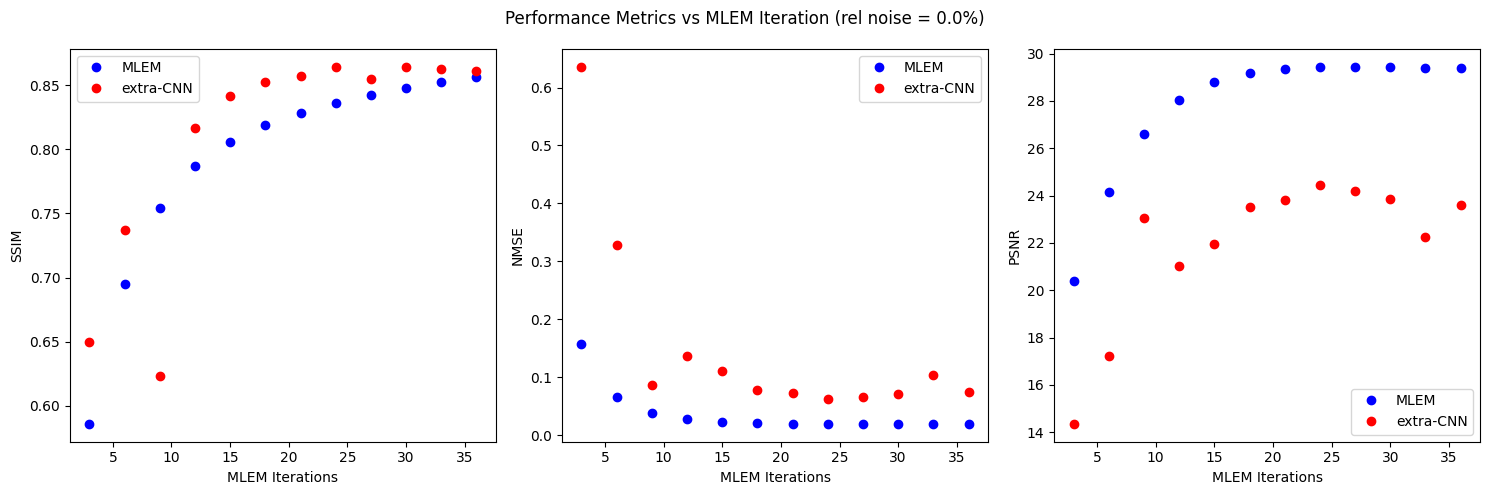

Evaluating iteration 3
Evaluating iteration 6
Evaluating iteration 9
Evaluating iteration 12
Evaluating iteration 15
Evaluating iteration 18
Evaluating iteration 21
Evaluating iteration 24
Evaluating iteration 27
Evaluating iteration 30
Evaluating iteration 33
Evaluating iteration 36


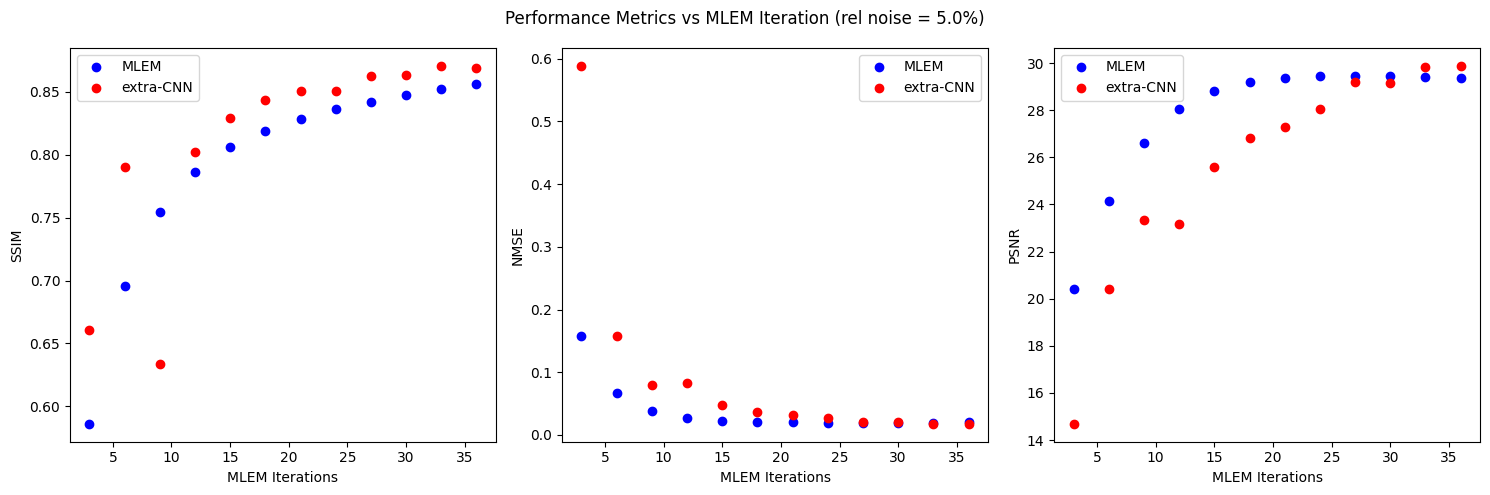

Evaluating iteration 3
Evaluating iteration 6
Evaluating iteration 9
Evaluating iteration 12
Evaluating iteration 15
Evaluating iteration 18
Evaluating iteration 21
Evaluating iteration 24
Evaluating iteration 27
Evaluating iteration 30
Evaluating iteration 33
Evaluating iteration 36


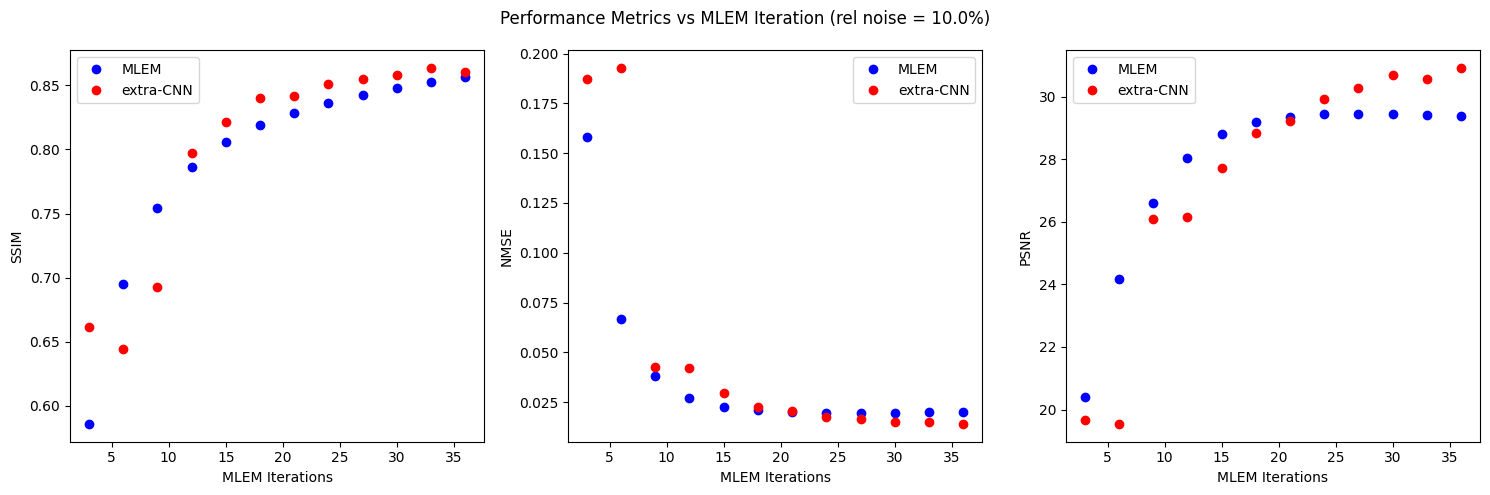

Evaluating iteration 3
Evaluating iteration 6
Evaluating iteration 9
Evaluating iteration 12
Evaluating iteration 15
Evaluating iteration 18
Evaluating iteration 21
Evaluating iteration 24
Evaluating iteration 27
Evaluating iteration 30
Evaluating iteration 33
Evaluating iteration 36


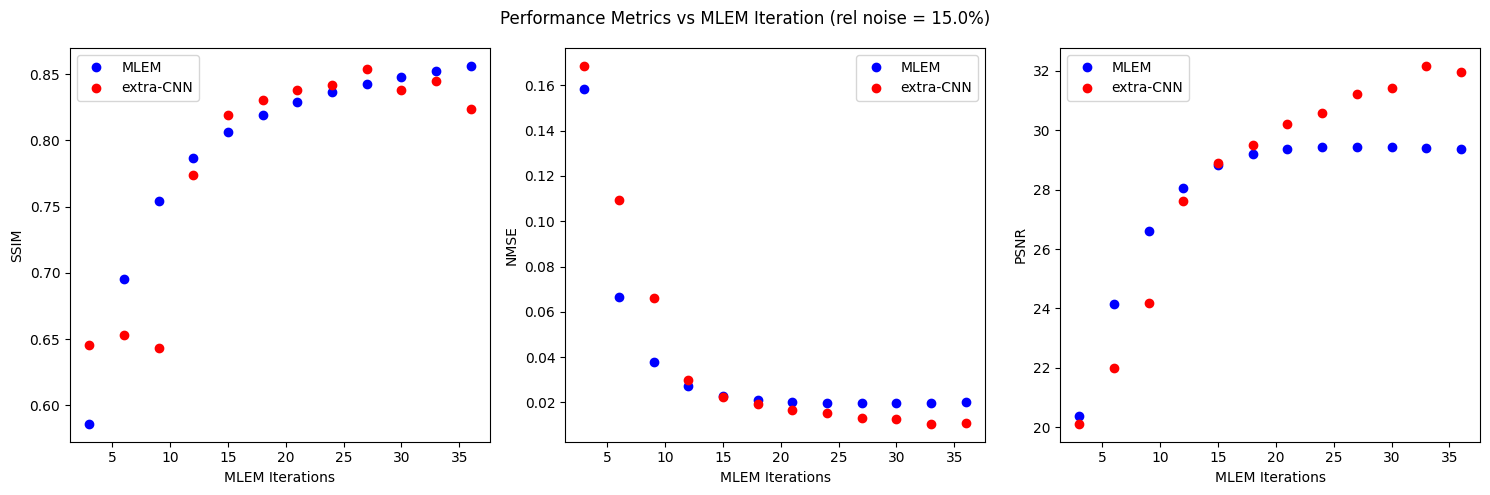

Evaluating iteration 3
Evaluating iteration 6
Evaluating iteration 9
Evaluating iteration 12
Evaluating iteration 15
Evaluating iteration 18
Evaluating iteration 21
Evaluating iteration 24
Evaluating iteration 27
Evaluating iteration 30
Evaluating iteration 33
Evaluating iteration 36


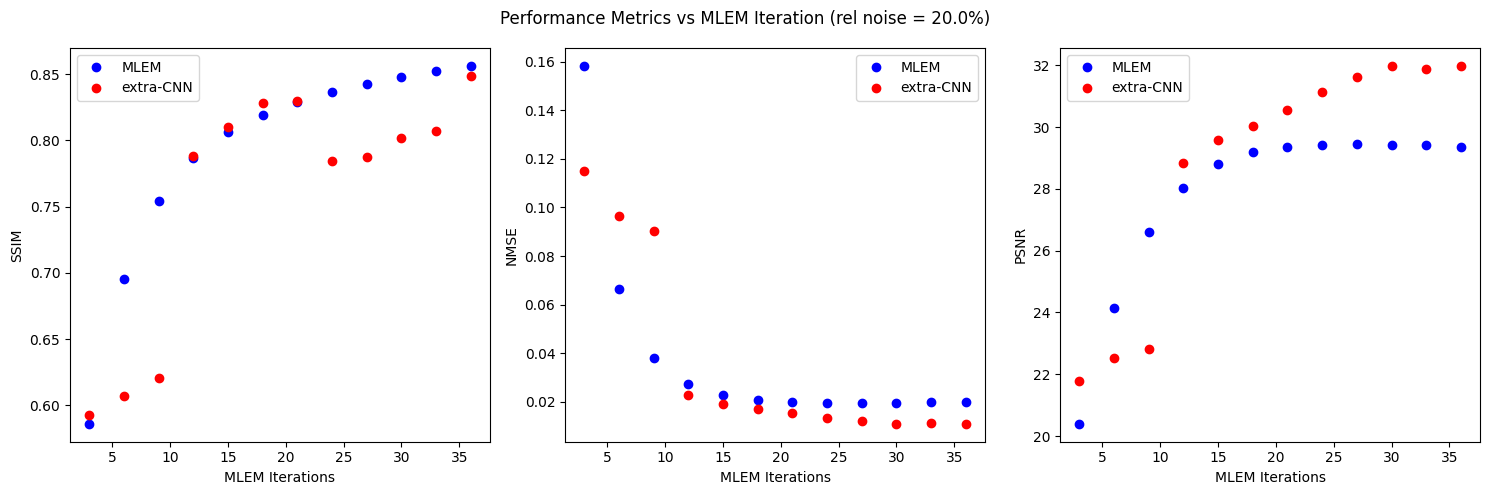

Evaluating iteration 3
Evaluating iteration 6
Evaluating iteration 9
Evaluating iteration 12
Evaluating iteration 15
Evaluating iteration 18
Evaluating iteration 21
Evaluating iteration 24
Evaluating iteration 27
Evaluating iteration 30
Evaluating iteration 33
Evaluating iteration 36


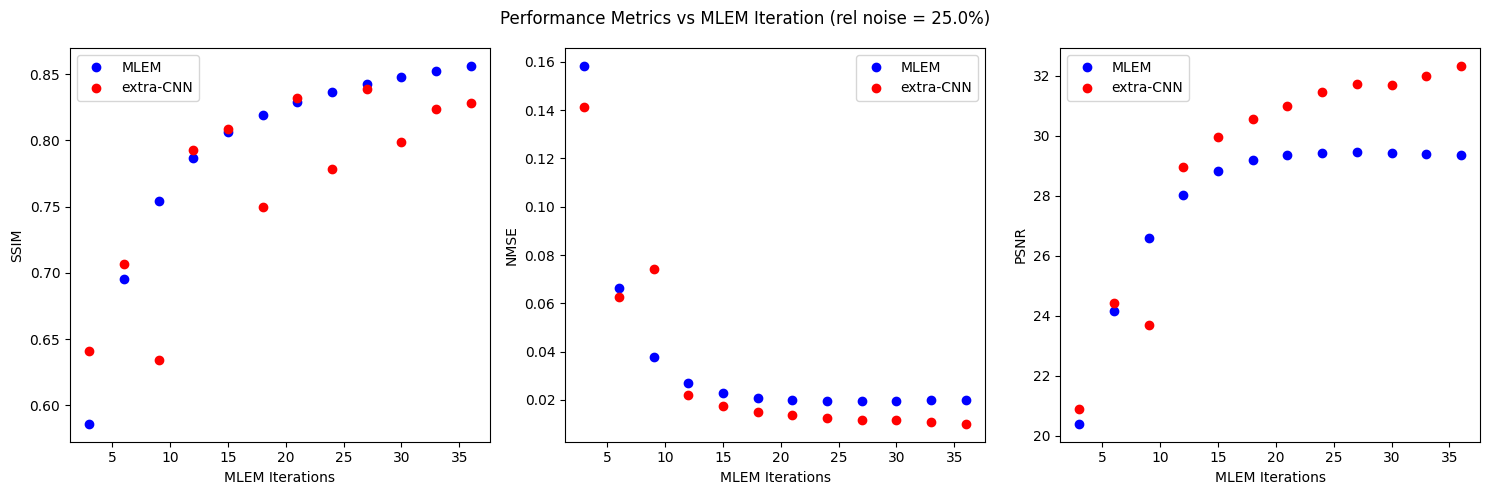

Evaluating iteration 3
Evaluating iteration 6
Evaluating iteration 9
Evaluating iteration 12
Evaluating iteration 15
Evaluating iteration 18
Evaluating iteration 21
Evaluating iteration 24
Evaluating iteration 27
Evaluating iteration 30
Evaluating iteration 33
Evaluating iteration 36


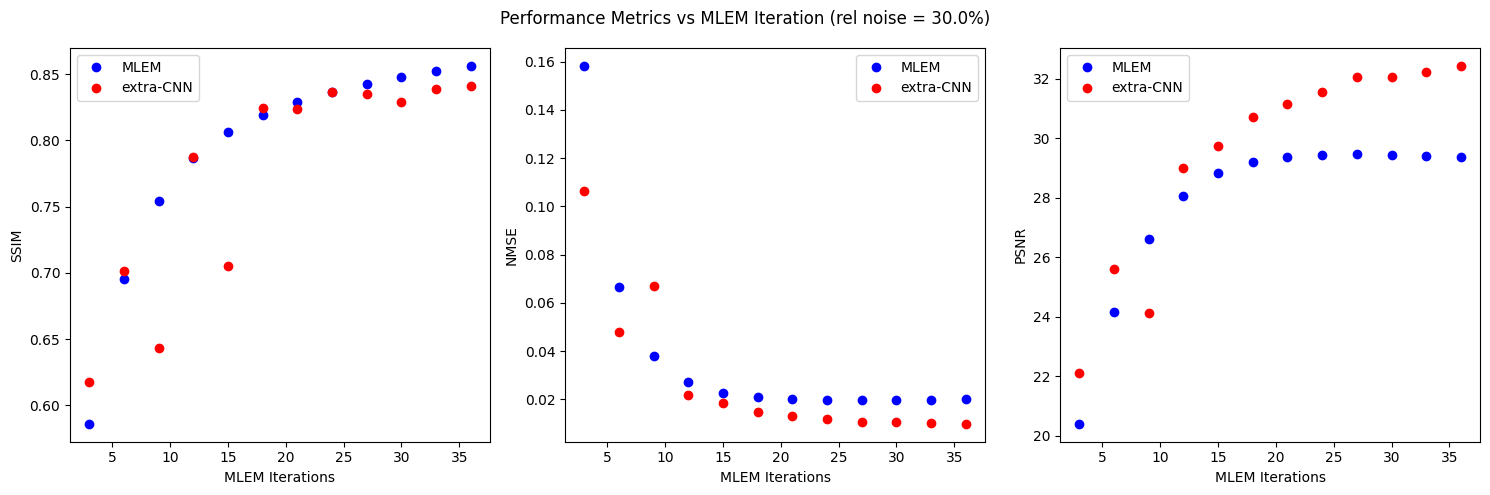

In [26]:
save_every = 3
iterations = list(range(save_every, 37, save_every))
noise_levels = [0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
noise_levels = np.array(noise_levels)

global_dr = float(test_ims_sn.max() - test_ims_sn.min())

for noise in noise_levels:

    prefix = "clean" if noise == 0 else f"noisy{noise}"
    mlem_prefix = '' if noise == 0 else f"noisy{noise}_"

    ssim_mlem, ssim_extra = [], []
    psnr_mlem, psnr_extra = [], []
    nmse_mlem, nmse_extra = [], []

    for it in iterations:
        print(f"Evaluating iteration {it}")

        mlem_test_raw = mlem_reco(sino, theta, it)
        #mlem_test_raw = np.load("/scratch/bggjem001/pet_datasets/Ryan_Data/reco_4_182.npy")
        mlem_test_raw = mlem_test_raw[None, ...] 

        #Sum-normalised version of MLEM reconstructions for metric comparison
        mlem_test_sn = np.array([sum_normalise(im) for im in mlem_test_raw])
        mlem_test_scaled = mlem_test_sn * scale


        #Loading the trained extra-CNN model
        model = extraCNN().to(device)
        model.load_state_dict(torch.load(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/model_weights/{prefix}_extra{it}_sn1.pth", map_location=device))
        model.eval()

        with torch.no_grad():
            enhanced = []
            for im in mlem_test_scaled:
                x = torch.from_numpy(im).unsqueeze(0).unsqueeze(0).float().to(device)
                out = model(x)
                enhanced.append(out.squeeze().cpu().numpy())

        enhanced = np.array(enhanced) / scale

        en_sn = np.array([sum_normalise(im) for im in enhanced])
        enhanced = en_sn * scale

        global_dr = float(test_ims_sn.max() - test_ims_sn.min())

        #NMSE
        nmse_vals =mean_squared_error(test_ims_sn[0], mlem_test_scaled[0]) / np.var(test_ims_sn[0])
        nmse_mlem.append(nmse_vals)

        #Getting SSIM vals for normal MLEM
        

        ssim_vals=ssim(test_ims_sn[0], mlem_test_scaled[0], data_range=global_dr)

        ssim_mlem.append(ssim_vals)

        #Getting PSNR vals for normal MLEM
        
        psnr_vals=psnr(test_ims_sn[0], mlem_test_scaled[0], data_range=global_dr)

        psnr_mlem.append(psnr_vals)

        #NMSE
        nmse_vals = mean_squared_error(test_ims_sn[0], enhanced[0]) / np.var(test_ims_sn[0])
        nmse_extra.append(nmse_vals)

        #SSIM for extra-CNN
    
        ssim_vals=ssim(test_ims_sn[0], enhanced[0], data_range=global_dr)

        ssim_extra.append(ssim_vals)

        #PSNR for extra-CNN
        psnr_vals = psnr(test_ims_sn[0], enhanced[0], data_range=global_dr)

        psnr_extra.append(psnr_vals)

        del enhanced, model
        torch.cuda.empty_cache()
    

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].plot(iterations, ssim_mlem, 'bo', label="MLEM")
    axes[0].plot(iterations, ssim_extra, 'ro', label="extra-CNN")
    axes[0].set_xlabel("MLEM Iterations")
    axes[0].set_ylabel("SSIM")
    axes[0].legend()

    axes[1].plot(iterations, nmse_mlem, 'bo', label="MLEM")
    axes[1].plot(iterations, nmse_extra, 'ro', label="extra-CNN")
    axes[1].set_xlabel("MLEM Iterations")
    axes[1].set_ylabel("NMSE")
    axes[1].legend()

    axes[2].plot(iterations, psnr_mlem, 'bo', label="MLEM")
    axes[2].plot(iterations, psnr_extra, 'ro', label="extra-CNN")
    axes[2].set_xlabel("MLEM Iterations")
    axes[2].set_ylabel("PSNR")
    axes[2].legend()

    plt.suptitle(f"Performance Metrics vs MLEM Iteration (rel noise = {noise*10}%)")

    plt.tight_layout()
    #plt.savefig(f"{base}/Plots/metrics_vs_iterations_{noise*10}_sn.png", dpi=300, bbox_inches='tight')
    plt.show()

In [27]:
mlem_test = np.load(f"{base}/datasets/images_train_sn.npy")

(-0.5, 181.5, 181.5, -0.5)

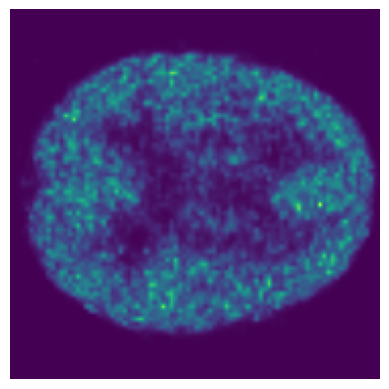

In [28]:
plt.imshow(mlem_test[25])
plt.axis("off")

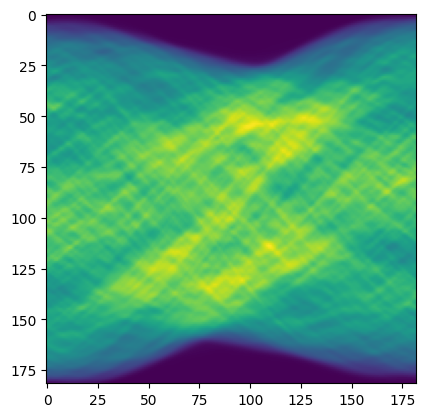

In [29]:
from skimage.transform import resize, radon, iradon

nxd = 182
theta = np.linspace(0., 180., max(nxd, 180), endpoint=False)

sino = radon(mlem_test[0], theta=theta, circle=True)

plt.imshow(sino)


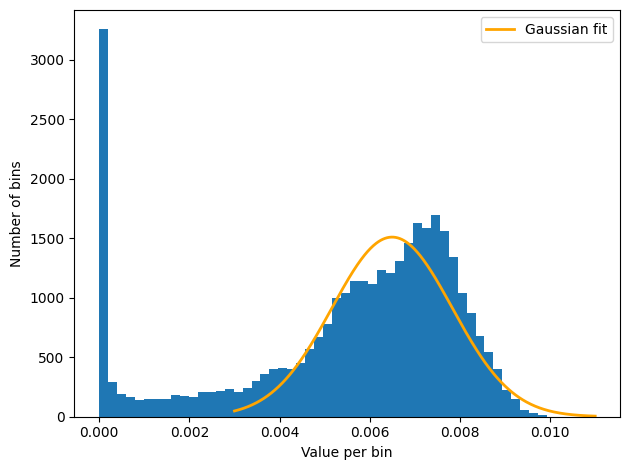

Fitted mean (mu): 0.00650
Fitted sigma:     0.00133
Fitted mean counts per bin (N): 0.0
Relative noise: 1240.7%


In [30]:
from scipy.optimize import curve_fit
from utils.noise_fcn import gaussian

n_bins = 50

counts_bin = sino.ravel()   # or whatever array this histogram is of
bin_heights, bin_edges = np.histogram(counts_bin, bins=n_bins)
bin_centres = bin_edges[:-1] + np.diff(bin_edges) / 2

# Window bracketing the bump; excludes the near-zero background spike
fit_min, fit_max = 0.003, 0.011

region = (bin_centres >= fit_min) & (bin_centres <= fit_max)
mask = region & np.isfinite(bin_heights) & (bin_heights > 0)
x = bin_centres[mask]
y = bin_heights[mask]

sigma_w = np.sqrt(y)
sigma_w[sigma_w == 0] = 1.0

# gaussian signature: (x, mean, amplitude, standard_deviation)
p0    = [0.007, 1700, 0.0012]
lower = [fit_min, 0, 1e-9]
upper = [fit_max, np.inf, np.inf]

popt, _ = curve_fit(gaussian, x, y, p0=p0, sigma=sigma_w,
                    absolute_sigma=True, bounds=(lower, upper), maxfev=20000)
mu_fit, A_fit, sigma_fit = popt
N = mu_fit

x_smooth = np.linspace(fit_min, fit_max, 500)
gauss_curve = gaussian(x_smooth, *popt)

plt.hist(counts_bin, bins=n_bins, edgecolor="none")
plt.plot(x_smooth, gauss_curve, color="orange", linewidth=2, label="Gaussian fit")
plt.xlabel("Value per bin")
plt.ylabel("Number of bins")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Fitted mean (mu): {mu_fit:.5f}")
print(f"Fitted sigma:     {sigma_fit:.5f}")
 
print(f"Fitted mean counts per bin (N): {N:.1f}")
rel_noise = 1 / np.sqrt(N)
print(f"Relative noise: {rel_noise*100:.1f}%")

In [31]:
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
from models.extramlem import extraCNN
from models.mlem_dataset import MLEMDataset
from utils.image_ops import normalise, sum_normalise
import gc
import matplotlib
matplotlib.use("Agg")  # no display on the cluster
import matplotlib.pyplot as plt

#Setup
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

CHECK_ONLY = True   # True: run intensity checks for every noise level, skip training
check_dir = "/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/intensity_checks"
import os; os.makedirs(check_dir, exist_ok=True)


#Intensity checks
def intensity_report(name, arr, frac=0.05):
    """Per-image stats averaged over the set. Support = pixels > frac * image max."""
    flat = np.asarray(arr, dtype=np.float64).reshape(len(arr), -1)
    sums = flat.sum(1)
    mean_in, cv_in = [], []
    for f in flat:
        v = f[f > frac * f.max()]
        mean_in.append(v.mean())
        cv_in.append(v.std() / v.mean())
    print(f"  {name:22s} n={len(flat):5d} shape={np.shape(arr)[1:]} "
          f"sum={sums.mean():.4g}±{sums.std():.2g} max={flat.max(1).mean():.4g} "
          f"neg={int((flat < 0).sum())} mean_in={np.mean(mean_in):.4g} "
          f"cv_in={np.mean(cv_in):.3f}")


def save_hists(groups, path, frac=0.05, max_ims=200):
    """Left: absolute values the network sees. Right: values / mean in support (shape only)."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    for name, arr in groups.items():
        flat = np.asarray(arr, dtype=np.float64).reshape(len(arr), -1)[:max_ims]
        vals, rel = [], []
        for f in flat:
            v = f[f > frac * f.max()]
            vals.append(v)
            rel.append(v / v.mean())
        a1.hist(np.concatenate(vals), bins=200, histtype="step", density=True, label=name)
        a2.hist(np.concatenate(rel), bins=200, histtype="step", density=True, label=name)
    a1.set(title="Network intensities (in support)", xlabel="pixel value", yscale="log")
    a2.set(title="Relative to mean in support", xlabel="value / mean", yscale="log")
    a1.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


images_train = np.load("/scratch/bggjem001/pet_datasets/datasets/images_train_sn.npy")
images_val   = np.load("/scratch/bggjem001/pet_datasets/datasets/images_val_sn.npy")

r_ims, r_mlem = [], []
idx = [0, 9, 14]

for i in idx:
    r_ims.append(np.load(f"/scratch/bggjem001/pet_datasets/Ryan_Data/truth_blurred_{i}_182.npy"))
    r_mlem.append(np.load(f"/scratch/bggjem001/pet_datasets/Ryan_Data/reco_{i}_182.npy"))

r_ims = np.array(r_ims)
r_mlem = np.array(r_mlem)
n_ryan = len(idx)

print("\n=== Ground truth, RAW (before any normalisation) ===")
intensity_report("NRM GT (_sn file)", images_train)
intensity_report("Ryan GT", r_ims)

assert r_ims.shape[1:] == images_train.shape[1:], \
    f"Shape mismatch: Ryan {r_ims.shape[1:]} vs NRM {images_train.shape[1:]}"

#Ryan's GT must go through the same normalisation as the _sn NRM targets
r_ims = np.array([sum_normalise(im) for im in r_ims])

assert np.allclose(images_train.reshape(len(images_train), -1).sum(1), 1.0, rtol=1e-3), \
    "images_train_sn.npy is not sum-normalised to 1"

images_train = np.concatenate((images_train, r_ims))

#Sum-norm changes the pixel intensities - they are now very small, and so before training we scale them up so that the model is able to learn properly
scale = 182 * 182

images_train_scaled = images_train * scale
images_val_scaled = images_val * scale

print("\n=== Ground truth, as seen by the network ===")
intensity_report("NRM GT", images_train_scaled[:-n_ryan])
intensity_report("Ryan GT", images_train_scaled[-n_ryan:])

noise_levels = [0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5]

save_every = 3

it = 9

for noise in noise_levels:

    #for it in range(save_every, 10, save_every):

    prefix = "clean" if noise == 0 else f"noisy{noise}"
    mlem_prefix = '' if noise == 0 else f"noisy{noise}_"

    print(f"Running MLEM iteration {it}")

    #Loading in the training, val and test data 
    mlem_images_train = np.load(f"/scratch/bggjem001/pet_datasets/datasets/{mlem_prefix}mlem{it}_train.npy")
    mlem_images_val = np.load(f"/scratch/bggjem001/pet_datasets/datasets/{mlem_prefix}mlem{it}_val.npy")

    mlem_images_train = np.concatenate((mlem_images_train, r_mlem))

    #Normalise the reconstructed images
    mlem_images_train = np.array([sum_normalise(im) * scale for im in mlem_images_train])
    mlem_images_val   = np.array([sum_normalise(im) * scale for im in mlem_images_val])

    print(f"\n=== MLEM inputs, noise {noise}, as seen by the network ===")
    intensity_report("NRM MLEM", mlem_images_train[:-n_ryan])
    intensity_report("Ryan MLEM", mlem_images_train[-n_ryan:])
    save_hists(
        {
            "NRM MLEM": mlem_images_train[:-n_ryan],
            "Ryan MLEM": mlem_images_train[-n_ryan:],
            "NRM GT": images_train_scaled[:-n_ryan],
            "Ryan GT": images_train_scaled[-n_ryan:],
        },
        f"{check_dir}/{prefix}_mlem{it}_hists.png",
    )

    if CHECK_ONLY:
        del mlem_images_train, mlem_images_val
        gc.collect()
        continue

    train_dataset = MLEMDataset(mlem_images_train, images_train_scaled)
    val_dataset = MLEMDataset(mlem_images_val, images_val_scaled)

    train_loader = DataLoader(train_dataset, batch_size=10, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=10)

    #Training the model
    model = extraCNN().to(device)
    loss_function = nn.MSELoss()
    optim = torch.optim.Adam(model.parameters(), lr=1e-3)

    train_loss, val_loss = [], []
    epochs = 30

    for epoch in range(epochs):

        model.train()
        running_train_loss = 0

        for mlem_im, target in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False):

            mlem_im = mlem_im.to(device).float()
            target = target.to(device).float()

            output = model(mlem_im)
            loss = loss_function(output, target)
            optim.zero_grad()
            loss.backward()
            optim.step()

            running_train_loss += loss.item()

        train_loss.append(running_train_loss / len(train_loader))

        #Validation 
        model.eval()
        running_val_loss = 0

        with torch.no_grad():

            for val_mlem_im, val_target in tqdm(val_loader, desc="Validation", leave=False):

                val_mlem_im = val_mlem_im.to(device).float()
                val_target = val_target.to(device).float()

                val_output = model(val_mlem_im)
                v_loss = loss_function(val_output, val_target)
                running_val_loss += v_loss.item()

        val_loss.append(running_val_loss / len(val_loader))
        print(f"Epoch {epoch+1} | Train Loss: {train_loss[-1]:.6f} | Val Loss: {val_loss[-1]:.6f}")

    #Saving the model
    torch.save(model.state_dict(), f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/model_weights/{prefix}_extra{it}_sn1.pth")

    np.save(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/model_weights/{prefix}_extra{it}_train_loss_sn1.npy", train_loss)
    np.save(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/model_weights/{prefix}_extra{it}_val_loss_sn1.npy", val_loss)

    print(f"Model {it} Trained")

    del mlem_images_train, mlem_images_val, train_dataset, val_dataset, model
    torch.cuda.empty_cache()
    gc.collect()


print("All models trained" if not CHECK_ONLY else "Checks done")


=== Ground truth, RAW (before any normalisation) ===
  NRM GT (_sn file)      n= 3500 shape=(182, 182) sum=1±5.7e-08 max=0.000249 neg=0 mean_in=6.73e-05 cv_in=0.471
  Ryan GT                n=    3 shape=(182, 182) sum=1.033e+04±2.6e+02 max=1 neg=0 mean_in=0.4357 cv_in=0.567

=== Ground truth, as seen by the network ===
  NRM GT                 n= 3500 shape=(182, 182) sum=3.312e+04±0.0019 max=8.249 neg=0 mean_in=2.229 cv_in=0.471
  Ryan GT                n=    3 shape=(182, 182) sum=3.312e+04±0.0022 max=3.209 neg=0 mean_in=1.4 cv_in=0.567
Running MLEM iteration 9

=== MLEM inputs, noise 0, as seen by the network ===
  NRM MLEM               n= 3500 shape=(182, 182) sum=3.312e+04±0.0019 max=4.222 neg=0 mean_in=1.925 cv_in=0.424
  Ryan MLEM              n=    3 shape=(182, 182) sum=3.312e+04±0.0021 max=3.632 neg=0 mean_in=1.352 cv_in=0.520
Running MLEM iteration 9

=== MLEM inputs, noise 0.5, as seen by the network ===
  NRM MLEM               n= 3500 shape=(182, 182) sum=3.312e+04±0.0

  NRM MLEM               n= 3500 shape=(182, 182) sum=3.312e+04±0.002 max=5.266 neg=0 mean_in=1.967 cv_in=0.426
  Ryan MLEM              n=    3 shape=(182, 182) sum=3.312e+04±0.0021 max=3.632 neg=0 mean_in=1.352 cv_in=0.520
Running MLEM iteration 9

=== MLEM inputs, noise 3.5, as seen by the network ===
  NRM MLEM               n= 3500 shape=(182, 182) sum=3.312e+04±0.0019 max=5.584 neg=0 mean_in=1.978 cv_in=0.429
  Ryan MLEM              n=    3 shape=(182, 182) sum=3.312e+04±0.0021 max=3.632 neg=0 mean_in=1.352 cv_in=0.520
Running MLEM iteration 9

=== MLEM inputs, noise 4.0, as seen by the network ===
  NRM MLEM               n= 3500 shape=(182, 182) sum=3.312e+04±0.0019 max=5.923 neg=0 mean_in=1.989 cv_in=0.434
  Ryan MLEM              n=    3 shape=(182, 182) sum=3.312e+04±0.0021 max=3.632 neg=0 mean_in=1.352 cv_in=0.520
Running MLEM iteration 9

=== MLEM inputs, noise 4.5, as seen by the network ===
  NRM MLEM               n= 3500 shape=(182, 182) sum=3.312e+04±0.0019 max=6.311